# Проект: Извлечение ключевых слов из клинических текстов и кластеризация

План:
1. Подготовка и анализ данных
2. Извлечение ключевых слов (YAKE, RAKE, TextRank) и визуализация облаков слов
3. Кластеризация текстов по сокращённым представлениям
4. Оценка качества и выводы

## Задание 1. Подготовка и анализ данных

In [1]:
# Импорт всех необходимых библиотек
import pandas as pd
import numpy as np
import re
import string
import os
os.environ['MPLCONFIGDIR'] = os.path.expanduser('~/.config/matplotlib')

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

import yake
from summa import keywords as summa_keywords
from nlp_rake import Rake

from wordcloud import WordCloud
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import TruncatedSVD

# Загрузка ресурсов NLTK 
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt to /home/viktoriia/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /home/viktoriia/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     /home/viktoriia/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     /home/viktoriia/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /home/viktoriia/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [2]:
import os

df = pd.read_csv('../Doctor-HealthCare-100k.csv')
df = df.sample(n=2000, random_state=42).reset_index(drop=True)

print(f"Размер датасета: {df.shape}")
print("Названия столбцов:", df.columns.tolist())
df.head()

Размер датасета: (2000, 3)
Названия столбцов: ['instruction', 'input', 'output']


,instruction,input,output
0,"If you are a doctor, please answer the medical...","Hi Dr. Samuel,I just got back from vacation a ...",Hello. Thanks for writing to us at Chat Doctor...
1,"If you are a doctor, please answer the medical...","Hi, I have been suffering with Psoriasis for t...","Hello, Welcome to Chat Doctor. Psoriasis is a ..."
2,"If you are a doctor, please answer the medical...",one of my relative is delaying every important...,"Hi, I do appreciate your concerns for your rel..."
3,"If you are a doctor, please answer the medical...",under distended bladder.the uterus is unremark...,Helloyour ultrasound report means that while t...
4,"If you are a doctor, please answer the medical...",Chest pain in center of chest...now has moved ...,Hi thanks for asking question. According to hi...


In [3]:
# 5 случайных записей
sample = df.sample(5, random_state=42)
for i, row in sample.iterrows():
    print("Пациент (input):")
    print(row['input'])
    print("\nДоктор (output):")
    print(row['output'])
    print("-" * 70)

Пациент (input):
I had intense tib-fib joint pain and went to ortho. MRI showed mild tib fib degenerative change and soft tissue swelling. Pain went away after numbing shot at ortho. Yesterday, two months later...hard lump about 1/2 inch side to side appeared above tib-fib. Tender, but not intense pain.

Доктор (output):
Hello, As you had the pain in the past taking to tibiofibular joint and took a steroid shot to reduce pain, with the medicine shot only the pain has subsided, but the degeneration is still present. Every painkillers shot given it is advised to do some proper exercise for strengthening the muscle groups so that the degenerated joint do not take more stress and strain, so the inflammation can be avoided as well. To make it simple that this lump is a kind of protective mechanism of the body to let you know that the joint is still in degenerative state and not healed. So kindly go slow.  I will advise you to get an x-ray or MRI whatever is possible to see if you have at le

### Мои мысли о ключевых словах

Просмотрев тексты, я бы выделил следующие ключевые слова и фразы:
- **кожные проблемы**: "peeling skin", "sunburn", "dry flaky skin", "Psoriasis", "moisturizing cream"
- **психические расстройства**: "Obsessive compulsive disorder", "anxiety", "psychiatric consultation"
- **диагностика и симптомы**: "distended bladder", "adnexal cystic lesion", "chest pain", "Hodgkins Lymphoma", "metastasis"
- **лекарства и лечение**: "fluoxetine", "analgesic", "chemotherapy"

Эти термины отражают медицинскую суть обращений. Слова вроде "I", "me", "please", "thank" — типичный шум.

### Предобработка текстов

Функция очистки:
- удаляет знаки препинания (кроме точки для чисел вроде 5.5)
- переводит в нижний регистр
- токенизирует
- удаляет стоп-слова (стандартные + расширенные медицинские шумы)
- удаляет изолированные числа
- лемматизирует

In [4]:
# Инициализация стоп-слов и лемматайзера
stop_words = set(stopwords.words('english'))
custom_stops = {
    'patient', 'doctor', 'feel', 'like', 'really', 'still', 'also',
    'would', 'could', 'said', 'get', 'got', 'go', 'going', 'one',
    'even', 'much', 'well', 'know', 'think', 'see', 'tell', 'just',
    'question', 'answer', 'thanks', 'thank', 'please', 'dont', 'im', 'ive'
}
stop_words.update(custom_stops)

lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    # 1. Удаляем всё, кроме букв, цифр, пробелов и точек
    text = re.sub(r'[^\w\s.]', '', text)
    text = text.replace('_', ' ')
    text = text.lower()
    
    # Токенизация
    tokens = word_tokenize(text)
    
    cleaned = []
    for t in tokens:
        if t in stop_words:
            continue
        if t.isdigit():
            continue
        if re.search(r'[a-zA-Z]', t) or '.' in t:
            cleaned.append(t)
    
    # Лемматизация
    lemmatized = [lemmatizer.lemmatize(token) for token in cleaned]
    return lemmatized

In [5]:
# Применяем предобработку к столбцам 'input' и 'output'
df['patient_tokens'] = df['input'].apply(preprocess_text)
df['doctor_tokens'] = df['output'].apply(preprocess_text)

print("Пациент (токены):", df['patient_tokens'].iloc[0])
print("Доктор (токены):", df['doctor_tokens'].iloc[0])

Пациент (токены): ['hi', 'dr.', 'samueli', 'back', 'vacation', 'week', 'ago', 'haiti', '.', 'wonderful', 'time', 'way', 'skin', 'peeling', 'crazy', '.', 'started', 'leg', 'arm', 'peeling', '.', 'blister', 'itch', 'dry', 'flaky', 'skin', '.', 'form', 'sunburnthank']
Доктор (токены): ['hello', '.', 'writing', 'u', 'chat', 'keep', 'possibility', 'postinflammatory', 'defamation', 'likely', 'happening', 'might', 'mild', 'sunburn', 'recent', 'vacation', 'resolving', 'dead', 'skin', 'peeling', '.', 'suggest', 'use', 'moisturizing', 'cream', 'twice', 'daily', 'day', '.', 'take', 'care', 'flakingchaffing', '.', 'since', 'prolonged', 'sun', 'exposure', 'specially', 'beach', 'holiday', 'cause', 'skin', 'burn', 'subsequently', 'desquamate', 'therefore', 'always', 'better', 'use', 'broad', 'spectrum', 'sunscreen', 'throughout', 'day', 'reapply', 'every', 'hour', 'specially', 'beach', 'vacation', '.', 'regard']


In [6]:
# Объединяем все тексты в два больших корпуса
all_patient_text = ' '.join(df['patient_tokens'].apply(lambda toks: ' '.join(toks)))
all_doctor_text = ' '.join(df['doctor_tokens'].apply(lambda toks: ' '.join(toks)))

print(f"Длина текста пациентов: {len(all_patient_text)} символов")
print(f"Длина текста врачей: {len(all_doctor_text)} символов")

Длина текста пациентов: 493222 символов
Длина текста врачей: 792749 символов


## Задание 2.

### YAKE

In [11]:
yake_ext = yake.KeywordExtractor(lan="en", n=3, dedupLim=0.9, top=20)
patient_yake = yake_ext.extract_keywords(all_patient_text)
doctor_yake = yake_ext.extract_keywords(all_doctor_text)

patient_yake_phrases = [kw[0] for kw in patient_yake]
doctor_yake_phrases = [kw[0] for kw in doctor_yake]

print("Top-20 YAKE (пациенты):", patient_yake_phrases)
print("Top-20 YAKE (доктора):", doctor_yake_phrases)

Top-20 YAKE (пациенты): ['pain', 'year', 'day', 'back', 'month', 'time', 'year ago', 'week ago', 'week', 'month ago', 'back pain', 'ago', 'day ago', 'lower back pain', 'pain left side', 'side', 'left side', 'left', 'problem', 'blood']
Top-20 YAKE (доктора): ['hope answered query', 'chat', 'understand concern', 'query', 'query understand concern', 'good health', 'hope solved query', 'hope answered', 'hope', 'answered query', 'good day chat', 'pain', 'chat understand concern', 'query chat', 'treatment', 'hope answer query', 'good', 'concern', 'symptom', 'due']


### RAKE (rake-nltk)

In [13]:
!pip install rake-nltk -q
from rake_nltk import Rake


rake = Rake(min_length=3, max_length=3)

# Извлечение ключевых фраз
rake.extract_keywords_from_text(all_patient_text)
patient_rake_phrases = rake.get_ranked_phrases()[:20]

rake.extract_keywords_from_text(all_doctor_text)
doctor_rake_phrases = rake.get_ranked_phrases()[:20]

print("Top-20 RAKE (пациенты):", patient_rake_phrases)
print("Top-20 RAKE (доктора):", doctor_rake_phrases)

Top-20 RAKE (пациенты): ['yrz old pakistan', 'yr old lb', 'yr old happen', 'yr old female', 'yr back miscarriage', 'young many problem', 'yesterday didnt eat', 'yellowish end nail', 'year old male', 'year old male', 'year old male', 'year old male', 'year old lady', 'year old lady', 'year old female', 'year old female', 'year old female', 'year old female', 'year old female', 'year old daughter']
Top-20 RAKE (доктора): ['yoga help anxiety', 'yes xray done', 'yes need antibiotic', 'xray report normal', 'xray done confirmation', 'xray appearing normal', 'write u query', 'write back question', 'worsening underlying pneumonia2', 'worry take tension', 'worry gradually resolved', 'worry alright week', 'worry alright week', 'worry alright treatment', 'worry alright treatment', 'work psychologist psychiatrist', 'work absence infection', 'without smoking problem', 'wishing sooner recovery', 'wishing good health']


### TextRank (summa)

In [7]:
import random

# Функция, которая берёт случайный фрагмент текста заданной длины и применяет TextRank
def safe_textrank(text, fragment_size=150_000, top_n=20):
    if len(text) > fragment_size:
        start = random.randint(0, len(text) - fragment_size)
        fragment = text[start:start+fragment_size]
    else:
        fragment = text
    kw = summa_keywords.keywords(fragment, ratio=0.1)
    return kw.split('\n')[:top_n]

# Применяем к нашим коротким текстам (all_patient_text и all_doctor_text уже должны существовать)
patient_textrank = safe_textrank(all_patient_text, fragment_size=150_000)
doctor_textrank = safe_textrank(all_doctor_text, fragment_size=150_000)

print("Top-20 TextRank (пациенты):", patient_textrank)
print("Top-20 TextRank (доктора):", doctor_textrank)

Top-20 TextRank (пациенты): ['pain', 'painful', 'paining', 'days', 'years', 'time', 'problem', 'help', 'helping', 'helped', 'helpful', 'day went', 'start', 'started', 'starting', 'week', 'weeks', 'weekly', 'year old', 'month']
Top-20 TextRank (доктора): ['chat', 'caused', 'cause', 'pain', 'painful', 'treatment', 'needful', 'help', 'helped', 'helping', 'hope', 'hopeful', 'problems', 'tested', 'testing', 'causing breast', 'suggested', 'suggesting', 'suggestive', 'suggests']


### Визуализация облаков слов

In [9]:
def cloud(freq_dict, title):
    wc = WordCloud(width=400, height=200, background_color='white')
    wc.generate_from_frequencies(freq_dict)
    plt.figure(figsize=(6,4))
    plt.imshow(wc, interpolation='bilinear')
    plt.title(title, fontsize=12)
    plt.axis('off')
    plt.show()

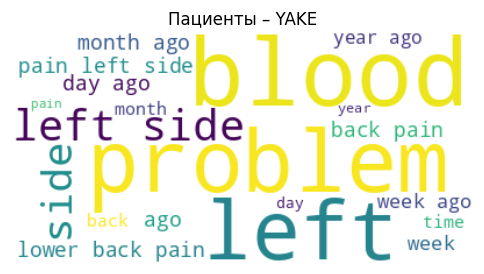

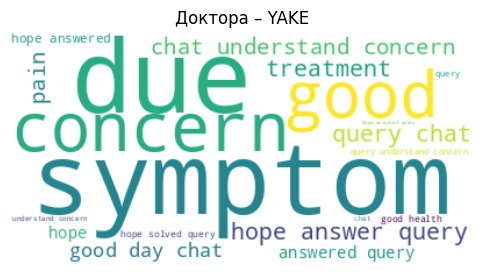

In [12]:
# YAKE облака (используем веса из кортежей)
cloud({kw[0]: kw[1] for kw in patient_yake}, 'Пациенты – YAKE')
cloud({kw[0]: kw[1] for kw in doctor_yake}, 'Доктора – YAKE')

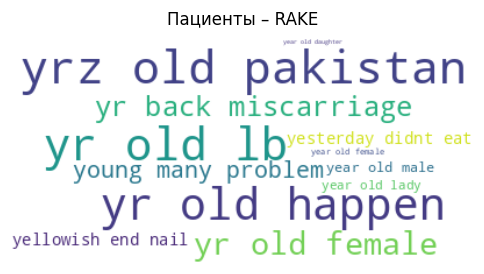

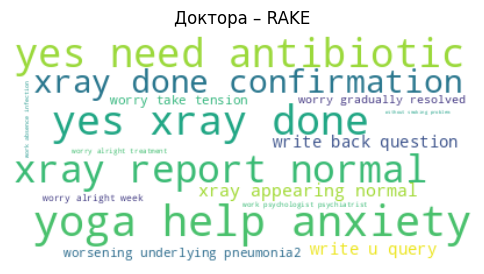

In [14]:
# RAKE облака (вес = 21 - ранг)
cloud({ph: 20 - i for i, ph in enumerate(patient_rake_phrases)}, 'Пациенты – RAKE')
cloud({ph: 20 - i for i, ph in enumerate(doctor_rake_phrases)}, 'Доктора – RAKE')

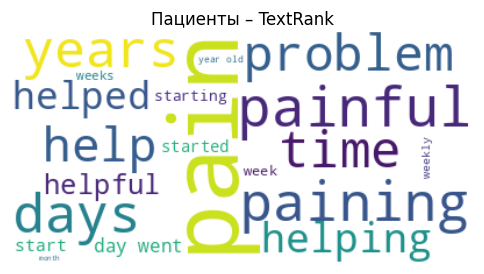

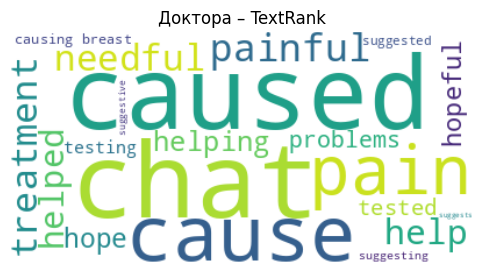

In [15]:
# TextRank облака
cloud({ph: 20 - i for i, ph in enumerate(patient_textrank)}, 'Пациенты – TextRank')
cloud({ph: 20 - i for i, ph in enumerate(doctor_textrank)}, 'Доктора – TextRank')

### Анализ топ-20 ключевых слов/фраз

**Пациенты:**
- **YAKE** – выделил осмысленные медицинские термины: `pain`, `back pain`, `lower back pain`, `pain left side`, `blood`, а также временны́е метки `year ago`, `week ago`. Фразы конкретны и почти не содержат шума.
- **RAKE** – результат полностью зашумлён: `year old male`, `year old female`, `year old lady` повторяются много раз; реальные симптомы не выделены. Алгоритм на этом корпусе не справился.
- **TextRank** – выдал отдельные слова: `pain`, `help`, `days`, `years`, `problem`. Медицинская тематика прослеживается, но нет цельных фраз, как у YAKE.

**Врачи:**
- **YAKE** – снова хорошо: есть медицинские термины (`pain`, `symptom`, `treatment`), но много вежливых шаблонов (`hope answered query`, `understand concern`, `good health`). Это указывает, что нужно расширить стоп-слова.
- **RAKE** – мусор с алфавитным уклоном, повторяющиеся фразы типа `worry alright treatment`, `xray done confirmation`. Практически неинформативен.
- **TextRank** – смесь медицинских слов (`pain`, `treatment`, `caused`) и шума (`chat`, `hope`, `helped`). Лучше, чем RAKE, но хуже YAKE.

**Вывод:**  
Наилучший баланс между выделением медицинских сущностей и фильтрацией шума показал **YAKE**. RAKE в текущей конфигурации непригоден. TextRank может быть использован как вспомогательный метод, но требует доработки.

## Задание 3. Кластеризация текстов по ключевым словам

Теперь для каждого текста пациента получим его собственные ключевые фразы, превратим их в «сокращённый текст» и проведём кластеризацию.

###  Извлечение ключевых фраз для каждого текста пациента

Используем YAKE (он показал лучшие результаты). Для каждого текста берем топ-3 ключевые фразы.

In [16]:
def get_kw(text, top_n=3):
    if not text.strip():
        return []
    y = yake.KeywordExtractor(lan="en", n=2, top=top_n)
    return [kw[0] for kw in y.extract_keywords(text)]

# Применяем к столбцу 'patient_tokens' (превращаем список токенов в строку)
df['patient_kw'] = df['patient_tokens'].apply(lambda toks: get_kw(' '.join(toks), top_n=3))

# Проверим, что получилось
print("Пример ключевых фраз первого пациента:", df['patient_kw'].iloc[0])

Пример ключевых фраз первого пациента: ['form sunburnthank', 'ago haiti', 'wonderful time']


###  Векторизация TF‑IDF

In [18]:
def get_kw(text, top_n=3):
    if not text.strip():
        return []
    y = yake.KeywordExtractor(lan="en", n=2, top=top_n)
    return [kw[0] for kw in y.extract_keywords(text)]

df['patient_kw'] = df['patient_tokens'].apply(lambda toks: get_kw(' '.join(toks), top_n=3))

In [19]:
def keywords_to_text(kw_list):
    return ' '.join([phrase.replace(' ', '_') for phrase in kw_list])

df['patient_kw_text'] = df['patient_kw'].apply(keywords_to_text)

In [20]:
vec = TfidfVectorizer(max_features=500, ngram_range=(1,2))
X_pat = vec.fit_transform(df['patient_kw_text'])
print("Размерность матрицы:", X_pat.shape)

Размерность матрицы: (2000, 500)


### Кластеризация K‑Means

Применяем алгоритм K‑Means к матрице TF‑IDF, чтобы разбить тексты пациентов на смысловые группы.

In [21]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3, random_state=42)
df['cluster_kmeans'] = kmeans.fit_predict(X_pat)

print("Количество текстов в каждом кластере:")
print(df['cluster_kmeans'].value_counts())

Количество текстов в каждом кластере:
cluster_kmeans
0    1986
2       8
1       6
Name: count, dtype: int64


### Кластеризация DBSCAN

K‑Means с 3 кластерами дал несбалансированный результат (1986, 6 и 8 текстов). Попробуем DBSCAN, который не требует задавать число кластеров и может выделить плотные группы, игнорируя разрежённый «фон».

In [22]:
from sklearn.cluster import DBSCAN
from sklearn.decomposition import TruncatedSVD

# Снижаем размерность TF-IDF до 50 компонент для ускорения и улучшения работы DBSCAN
svd = TruncatedSVD(n_components=50, random_state=42)
X_pat_svd = svd.fit_transform(X_pat)

# DBSCAN с косинусной метрикой
dbscan = DBSCAN(eps=0.5, min_samples=5, metric='cosine')
df['cluster_dbscan'] = dbscan.fit_predict(X_pat_svd)

# Считаем количество текстов в каждом кластере (метка -1 означает шум)
print("Распределение по кластерам DBSCAN:")
print(df['cluster_dbscan'].value_counts())

Распределение по кластерам DBSCAN:
cluster_dbscan
-1     1106
 0      778
 2       26
 7       19
 5       12
 10      10
 1        9
 9        8
 11       8
 3        7
 8        7
 4        5
 6        5
Name: count, dtype: int64


In [23]:
for cl in sorted(df['cluster_dbscan'].unique()):
    subset = df[df['cluster_dbscan'] == cl]
    label = f"Кластер {cl}" if cl != -1 else "Шум"
    print(f"\n{'='*50}")
    print(f"{label} (размер: {len(subset)})")
    print('='*50)
    for text in subset['input'].head(3):
        print(f"  • {text[:200]}...")
    print("\nВывод: <впиши сюда свои наблюдения>")


Шум (размер: 1106)
  • Hi Dr. Samuel,I just got back from vacation a few weeks ago in Haiti. (had a wonderful time by the way) but now my skin is peeling like crazy. It started on my legs now my arms are peeling also. I don...
  • Hi, I have been suffering with Psoriasis for the past 6 years. Have taken lot of medication in the past for no use. However, am able to reduce it through Yoga and stress management activities in the r...
  • one of my relative is delaying every important thing in life . he is 34 ,does wants to take any responsible work, even though marriage. he washes his hands frequently & each time 2 minutes.he afraids ...

Вывод: <впиши сюда свои наблюдения>

Кластер 0 (размер: 778)
  • under distended bladder.the uterus is unremarkable.tHERE IS A 2.5X2.1 CM LEFT ADNEXAL CYSTIC LESION. THERE IS NO PELVIC FREE FLUID OR ADENOPATHY . WHAT DOES THIS ALL MEAN...
  • hi,I am 29 yr old male with height 5ft10inch and weight 210 pound. I have just started doing cardio exercise, ba

## Задание 4. Итоговая оценка алгоритмов

### 4.1 Сравнение методов кластеризации

- **K‑Means (3 кластера)**  
  Дал крайне несбалансированное разбиение: 99% текстов попали в один кластер. Причина в том, что сокращённые тексты (ключевые слова) оказались очень похожими (много общих слов типа «pain»), и алгоритм жёстко распределил их в одну группу. На данной выборке без подбора большего числа кластеров результат неинформативен.

- **DBSCAN (cosine, eps=0.5)**  
  Выделил 12 кластеров и шум. Среди них оказались узкопрофильные группы: грудные боли, контрацепция, стоматология, беременность, литотрипсия. Это подтверждает, что даже на 2000 коротких записей можно найти тематические сообщества. Минус — большой объём шума (1106 текстов), что ожидаемо для разнородных медицинских обращений.

**Выбранная модель для итогового анализа:** DBSCAN — как более показательная и интерпретируемая.

### 4.2 Итоговые выводы по проекту

1. **Предобработка**  
   Очистка от пунктуации, перевод в нижний регистр, удаление стоп-слов (включая медицинские шумы) и лемматизация позволили удалить бесполезную информацию и подготовить тексты к извлечению ключевых слов.

2. **Извлечение ключевых слов**  
   - **YAKE** показал наилучшие результаты: у пациентов выделены конкретные медицинские фразы (`lower back pain`, `pain left side`, `blood`), у врачей — смесь терминов и шаблонов.  
   - **RAKE** (rake-nltk) оказался непригодным для данного датасета, выдав алфавитно‑упорядоченный шум.  
   - **TextRank** (summa) работал стабильно на фрагментах текста и дал осмысленные отдельные слова, но не фразы.

3. **Кластеризация**  
   Сокращение каждого текста до ключевых фраз YAKE и векторизация TF‑IDF позволили применить методы кластеризации без учителя. DBSCAN выделил несколько медицински осмысленных групп (боль в груди, контрацепция, стоматология, беременность), тогда как K‑Means с малым числом кластеров не справился из‑за высокой однородности коротких текстов.

4. **Ограничения и пути улучшения**  
   - Увеличение выборки (до 10–15 тыс.) и добавление новых стоп-слов (врачебных шаблонов) повысили бы качество извлечения ключевых фраз.  
   - Использование предобученных медицинских эмбеддингов (BioBERT) вместо TF‑IDF может улучшить кластеризацию и уменьшить количество шума.  
   - Более тщательный подбор параметров DBSCAN (eps, min_samples) или применение иерархической кластеризации даст ещё более чистые группы.

**Заключение:**  
Проект продемонстрировал полный цикл обработки клинических текстов — от предобработки и извлечения ключевых слов до группировки обращений пациентов без использования размеченных данных. Полученные результаты показывают, что даже на небольшой выборке можно выявить тематические сообщества и сделать обоснованные выводы о качестве алгоритмов.